In [56]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress
import PyQt5
# %matplotlib qt
import mne

In [57]:
subject = "07"

# **Data Loading and informations**

## loading

In [58]:
# raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif", preload=True, allow_maxshield=True)

In [59]:
# 41sec
epochs = mne.read_epochs(f"/Volumes/My Passport/Analysis/BIDS/sub-{subject}/meg/sub-{subject}_task-FRINT_proc-clean_split-01_epo.fif", preload=True)
metadatas = pd.read_csv(f"/Volumes/My Passport/Data comportement/data clean behavior MEG/FRINT_MEG_S{subject}.csv", index_col = 0)

In [60]:
mne.set_log_level('WARNING')

## metadatas modifications

In [61]:
metadatas.columns = metadatas.columns.str.strip()
df_filtered = metadatas.copy()
# Exemple: sélection des colonnes rotangle_1 à rotangle_7
rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
presangle_cols = [f'presangle_{i}' for i in range(1, 8)]
df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
df_filtered["length of sequence"] = df_filtered["Seqlen"]
df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)
df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered = df_filtered.dropna(subset=["final_angle"])
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
df_radian["target"] = np.deg2rad(df_filtered['target'])
df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])
df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian['stimulus_rotations_degrees'] = df_filtered['stimulus_rotations']
df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
metadatas_clean = df_radian.copy()

In [62]:
if float(subject)%3 == 0 :
    color_mapping = {np.deg2rad(0): 'blue',  np.deg2rad(45): 'green', np.deg2rad(-45): 'red'}
elif float(subject)%3 == 1 :
    color_mapping = {np.deg2rad(0): 'red',  np.deg2rad(45): 'blue', np.deg2rad(-45): 'green'}
elif float(subject)%3 == 2 : 
    color_mapping = {np.deg2rad(0): 'green',  np.deg2rad(45): 'red', np.deg2rad(-45): 'blue'}
color_mapping

{0.0: 'red', 0.7853981633974483: 'blue', -0.7853981633974483: 'green'}

In [63]:
colors = []
colors_extended = []
for i in range(len(metadatas_clean)) : 
    colors_one_extended = []
    colors_one = []
    for x in metadatas_clean["stimulus_rotations"].iloc[i]:
        colors_one.append(color_mapping[x])
        colors_one_extended.extend(color_mapping[x])
    colors.append(colors_one)
    colors_extended.extend(colors_one)

metadatas_clean["color_seen"] = colors

In [64]:
block_extended = []
rotation_radians_extended = []
rotation_degrees_extended = []
expected_angles_extended = []
presented_angles_extended = []
count = 0
for i in range(len(metadatas_clean)) :
    for element in range(len(metadatas_clean["stimulus_rotations"].iloc[i])) :
        block_extended.append(metadatas_clean["Block"].iloc[i])
        presented_angles_extended.append(metadatas_clean["presented_angles"].iloc[i][element])
        rotation_radians_extended.append(metadatas_clean["stimulus_rotations"].iloc[i][element])
        rotation_degrees_extended.append(metadatas_clean["stimulus_rotations_degrees"].iloc[i][element])
        expected_angles_extended.append(metadatas_clean["expected_angles"].iloc[i][element])   
        count +=1 

In [65]:
epochs.metadata
meta = epochs.metadata.copy()
meta.index = meta["index"]
meta = meta.drop(columns = ["Stim/S1", "Stim/S2", "Stim/S3", "Stim/S4", "Stim/S5", "Stim/S6", "Stim/S7", "SeqStart", "BlockStart", "Resp", "RespProb", "index"])

meta["stim_color"] = colors_extended
    
meta["block"] = block_extended
meta["rotation_in_radian"] = rotation_radians_extended
meta["rotation_in_degrees"] = rotation_degrees_extended
meta["expected_angles"] = expected_angles_extended
meta["presented_angles"] = presented_angles_extended
epochs.metadata = meta
meta

,event_name,stim_color,block,rotation_in_radian,rotation_in_degrees,expected_angles,presented_angles
index,,,,,,,
0,Stim/S1,red,1,0.000000,0.0,2.729659,2.729659
1,Stim/S2,green,1,-0.785398,-45.0,3.248938,4.034336
2,Stim/S3,green,1,-0.785398,-45.0,3.108001,3.893399
3,Stim/S4,red,1,0.000000,0.0,2.830755,2.830755
4,Stim/S5,red,1,0.000000,0.0,3.336505,3.336505
...,...,...,...,...,...,...,...
1435,Stim/S1,green,10,-0.785398,-45.0,2.561027,3.346425
1436,Stim/S2,blue,10,0.785398,45.0,1.796258,1.010860
1437,Stim/S3,green,10,-0.785398,-45.0,2.256235,3.041633


We need to check that the epochs and the metadatas are aligned. If some epochs were rejected that can cause a misalignement

In [66]:
print("length of epochs :",len(epochs))
print("length of stimuli :", len(colors_extended))
print("length of epochs conserved from the beginning :", len(epochs.selection))
print("length of rotations :",len(rotation_radians_extended))
print("length of epochs :", len(epochs))

length of epochs : 1440
length of stimuli : 1440
length of epochs conserved from the beginning : 1440
length of rotations : 1440
length of epochs : 1440


## last preprocessing steps

reapply a low and high pass filter

In [67]:
# epochs.filter(l_freq=0.5, h_freq=16)

apply a baseline

In [68]:
epochs.apply_baseline((None, None))
# epochs.apply_baseline((None, 0))

Number of events,1440
Events,Stim/S1: 360Stim/S2: 270Stim/S3: 270Stim/S4: 180Stim/S5: 180Stim/S6: 90Stim/S7: 90
Time range,-0.200 – 1.500 s
Baseline,-0.200 – 1.500 s


informations

In [69]:
epochs

Number of events,1440
Events,Stim/S1: 360Stim/S2: 270Stim/S3: 270Stim/S4: 180Stim/S5: 180Stim/S6: 90Stim/S7: 90
Time range,-0.200 – 1.500 s
Baseline,-0.200 – 1.500 s


In [70]:
epochs.event_id

{'Stim/S1': 5,
 'Stim/S2': 6,
 'Stim/S3': 7,
 'Stim/S4': 8,
 'Stim/S5': 9,
 'Stim/S6': 10,
 'Stim/S7': 11}

In [71]:
mne.channel_indices_by_type(epochs.info)

{'eeg': [],
 'csd': [],
 'stim': [326],
 'eog': [0, 1],
 'ecg': [2],
 'emg': [],
 'misc': [321, 322, 323, 324, 325],
 'resp': [],
 'chpi': [],
 'exci': [3],
 'ias': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'syst': [327],
 'seeg': [],
 'dipole': [],
 'gof': [],
 'bio': [],
 'ecog': [],
 'dbs': [],
 'temperature': [],
 'gsr': [],
 'ref_meg': [],
 'mag': [15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72,
  75,
  78,
  81,
  84,
  87,
  90,
  93,
  96,
  99,
  102,
  105,
  108,
  111,
  114,
  117,
  120,
  123,
  126,
  129,
  132,
  135,
  138,
  141,
  144,
  147,
  150,
  153,
  156,
  159,
  162,
  165,
  168,
  171,
  174,
  177,
  180,
  183,
  186,
  189,
  192,
  195,
  198,
  201,
  204,
  207,
  210,
  213,
  216,
  219,
  222,
  225,
  228,
  231,
  234,
  237,
  240,
  243,
  246,
  249,
  252,
  255,
  258,
  261,
  264,
  267,
  270,
  273,
  276,
  279,
  282,
  285,
  288,
  291,
  294,
  297,
  300,
  30

# **Navigating through Evoked Responses**

evoked.plot_joint()
contrast = mne.combine_evoked([evoked2, evoked3], weights=[-1, 1])
contrast.plot(gfp=True)
epochs[10].average().plot_joint()
fig = epochs.compute_psd(tmax=0, fmax=20).plot()
#evoked.plot_topomap(times=[0.1, 0.2, 0.3])

On a nos epochs, qui sont timelocked à 0sec, à partir de chaque élément vu. On calcule le PSD (Power Spectral Density), qui mesure le niveau d'énergie du signal à chaque fréquence. On a mit des high et low pass, à 0 et 16Hz.

/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


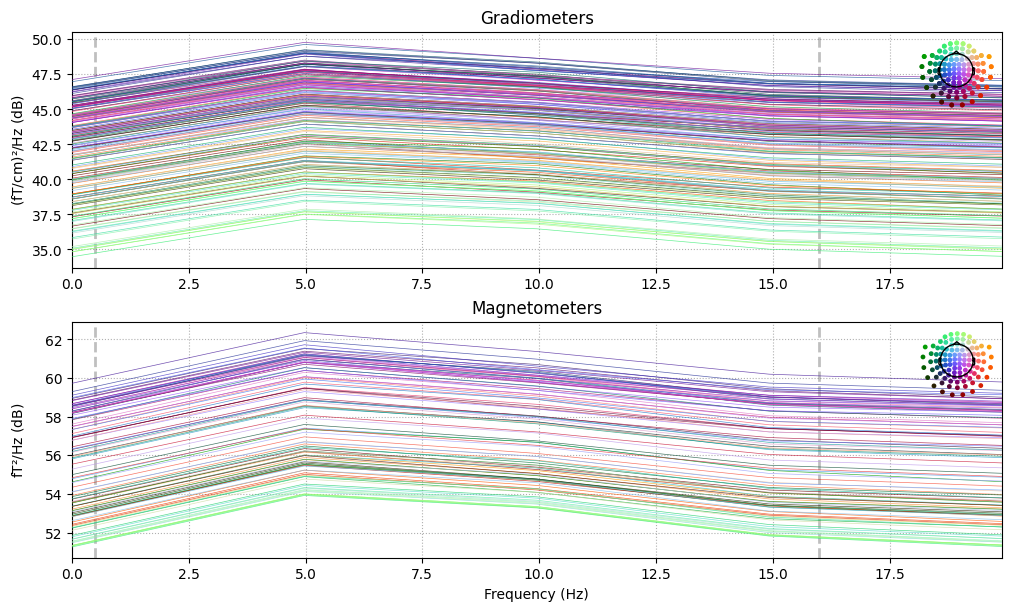

In [72]:
psd = epochs.compute_psd(tmax=0, fmax=20).plot()
psd

On peut aussi plot un seul epoch, et voir que seul, il n'est pas très utile de les regarder, la moyenne fait ressortir des pattern.

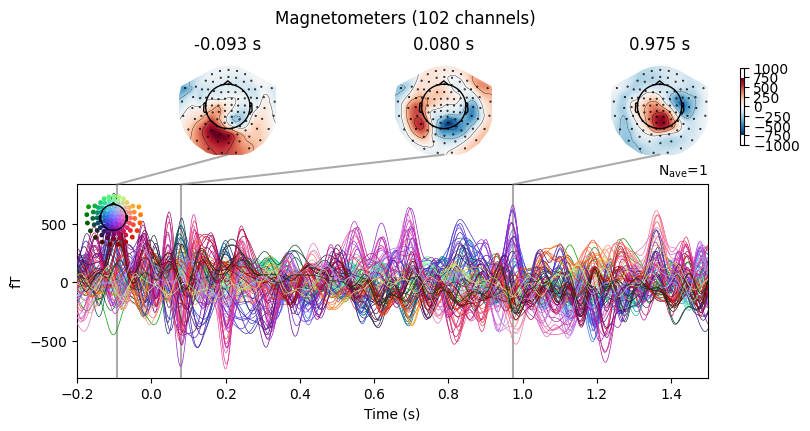

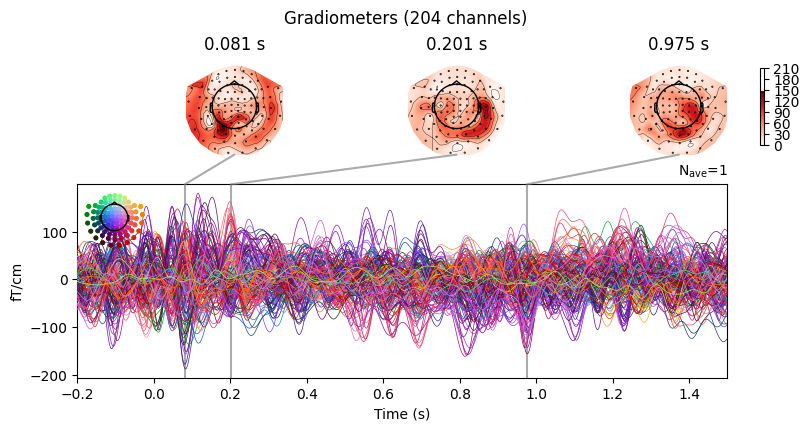

In [73]:
plt.close('all')
epochs[10].average().plot_joint(show=True)
plt.show()

On calcule les evoked, la moyenne de toutes les epochs à chaque pas de temps.

In [74]:
evoked = epochs.average()
evoked

Condition,0.25 × Stim/S1 + 0.19 × Stim/S2 + 0.19 × Stim/S3 + 0.12 × Stim/S4 + 0.12 × Stim/S5 + 0.06 × Stim/S6 + 0.06 × Stim/S7
Data kind,average
Timepoints,1701 samples
Channels,306 channels
Number of averaged epochs,1440
Time range (secs),-0.2 – 1.5
Baseline (secs),-0.200 – 1.500 s


In [75]:
print(evoked)

<Evoked | '0.25 × Stim/S1 + 0.19 × Stim/S2 + 0.19 × Stim/S3 + 0.12 × Stim/S4 + 0.12 × Stim/S5 + 0.06 × Stim/S6 + 0.06 × Stim/S7' (average, N=1440), -0.2 – 1.5 s, baseline -0.2 – 1.5 s, 306 ch, ~4.5 MB>


On peut plot les evoked dans le temps et voir leur variation de champ magnétique. On a mit une baseline pour mieux visualiser. 

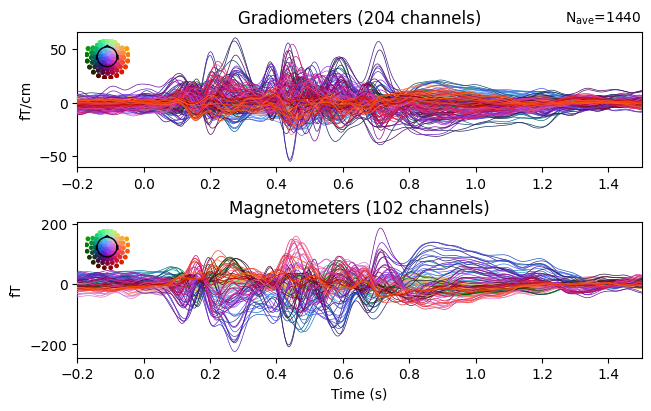

In [76]:
evoked.plot(show = False)

plot_joint() permet de voir les topomap aux moments qui sont les plus pertinents d'après MNE. 

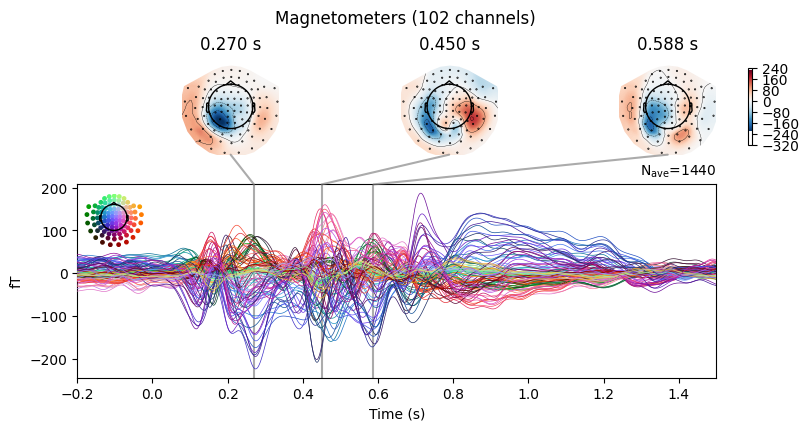

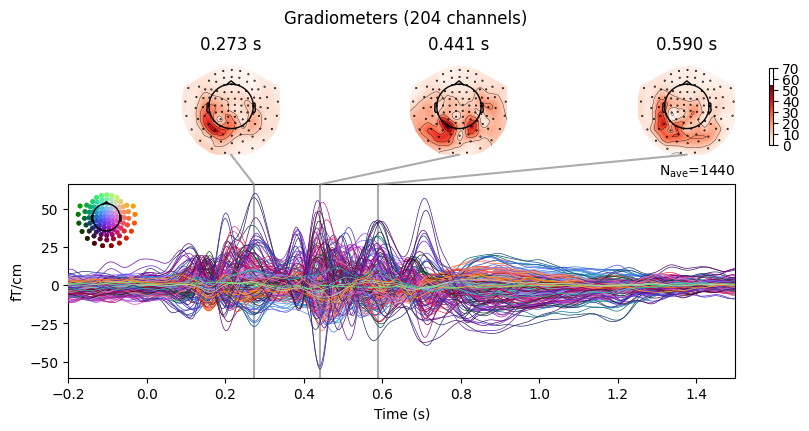

In [77]:
plt.close('all')
evoked.plot_joint()
plt.show()

/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


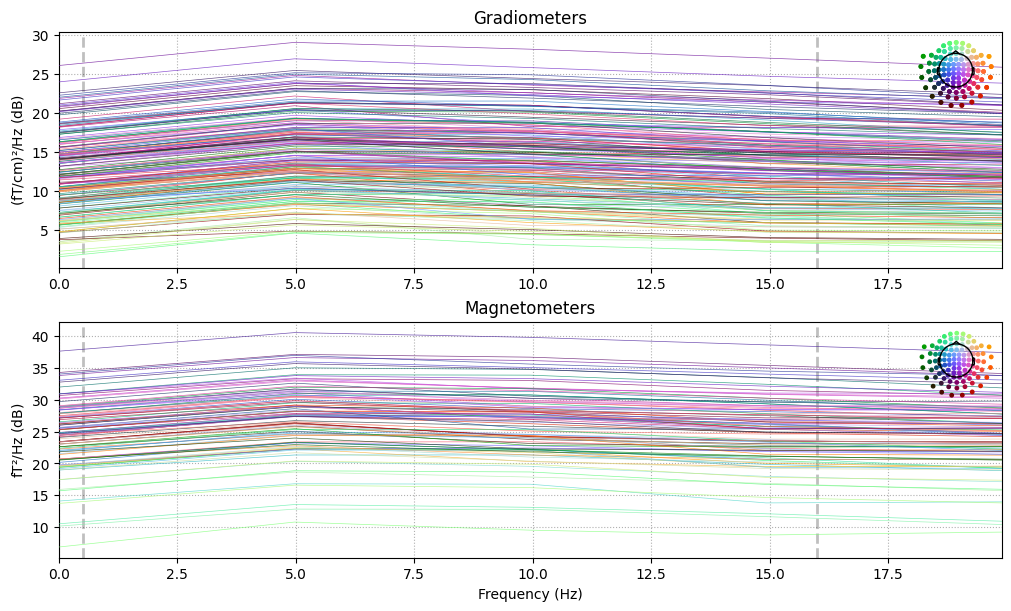

In [78]:
evoked.plot_psd(tmax=0, fmax=20)

On peut plot la topomap des evoked à des moments choisis. La topomap est celle des magnétomètres. Les magnétomètres mesurent le champs magnétique verticalement, on peut dire donc que il y a un signal entre les pool bleus et les pools rouges, pq quand les neurones s'activent, les atomes ont un spleen particulier, et créent un champs magnétique en forme de cercles là autour de cet atome, ce qui explique que on a des signaux verticaux qui vont vers le haut et verrs le bas. on ne regarde pas les gradiomètres car ils mesurent la dérivée du champ magnétique à un point, et sont horizontaux, très peu pertinents pour plot, ça nous donne pas tant d'information.   

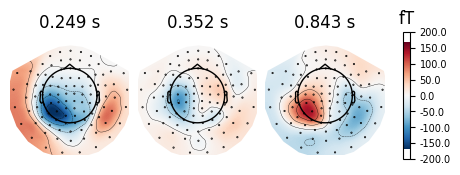

In [79]:
evoked.plot_topomap(times=[0.249, 0.352, 0.843], show=False) #, ch_type="mag")


# **Further comparision analysis**

In [80]:
meta

,event_name,stim_color,block,rotation_in_radian,rotation_in_degrees,expected_angles,presented_angles
index,,,,,,,
0,Stim/S1,red,1,0.000000,0.0,2.729659,2.729659
1,Stim/S2,green,1,-0.785398,-45.0,3.248938,4.034336
2,Stim/S3,green,1,-0.785398,-45.0,3.108001,3.893399
3,Stim/S4,red,1,0.000000,0.0,2.830755,2.830755
4,Stim/S5,red,1,0.000000,0.0,3.336505,3.336505
...,...,...,...,...,...,...,...
1435,Stim/S1,green,10,-0.785398,-45.0,2.561027,3.346425
1436,Stim/S2,blue,10,0.785398,45.0,1.796258,1.010860
1437,Stim/S3,green,10,-0.785398,-45.0,2.256235,3.041633


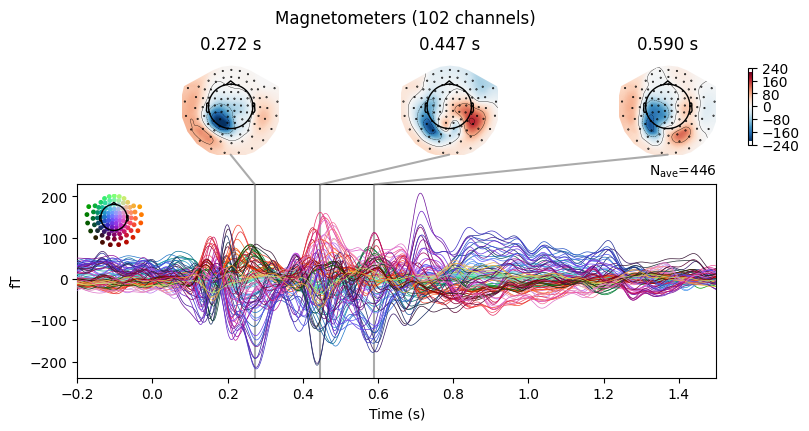

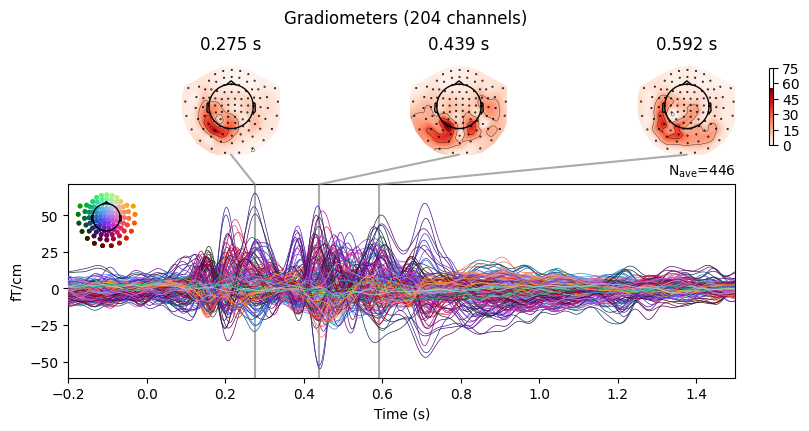

[<Figure size 800x420 with 6 Axes>, <Figure size 800x420 with 6 Axes>]

In [113]:
epochs["stim_color=='red'"].average().plot_joint(show= True)

/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


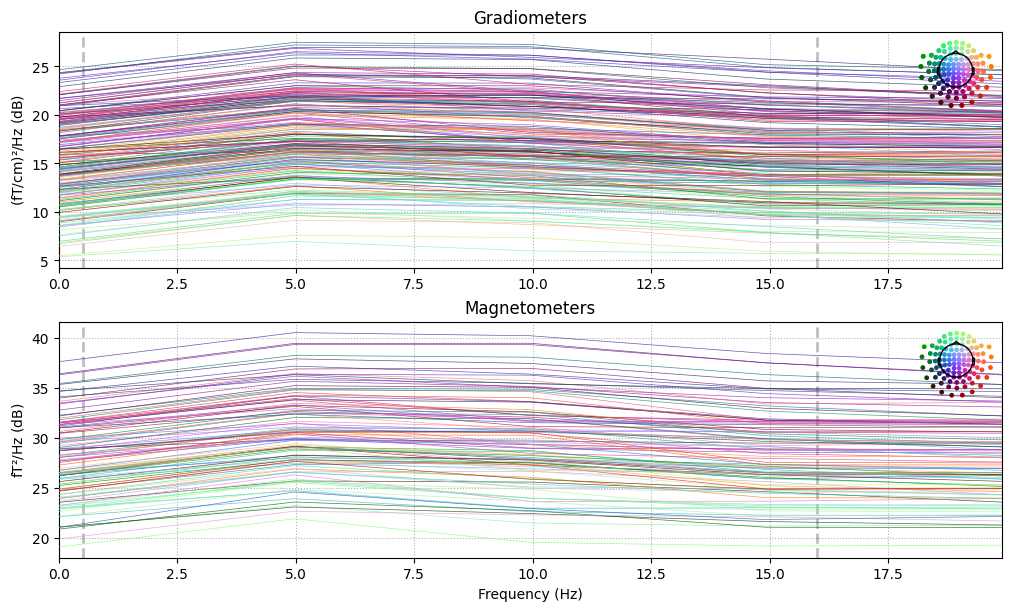

In [117]:
evoked_red.compute_psd(tmax=0, fmax=20).plot()


/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


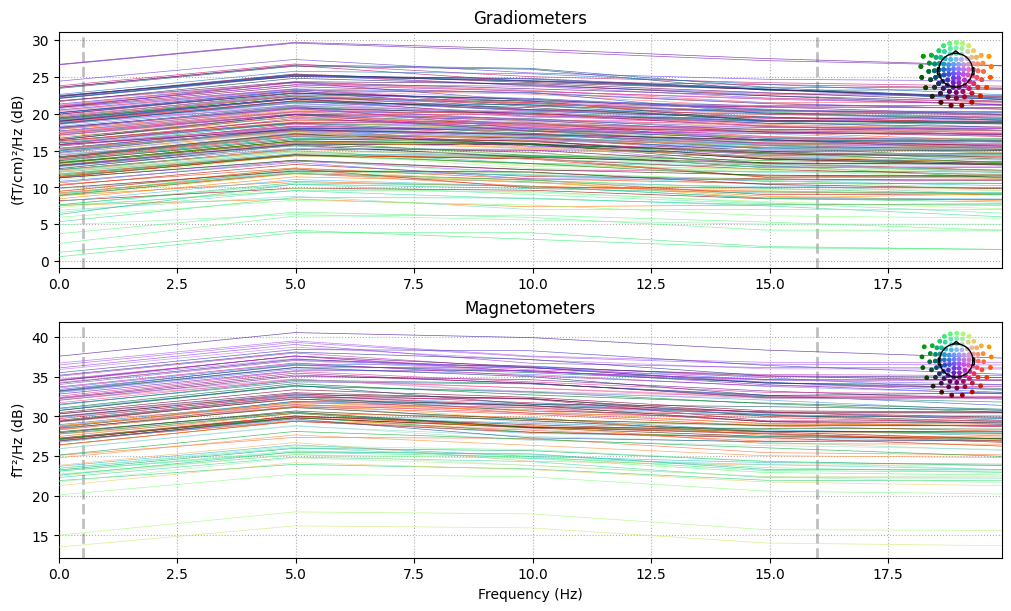

In [118]:
evoked_green.compute_psd(tmax=0, fmax=20).plot()

In [82]:
epochs.metadata

,event_name,stim_color,block,rotation_in_radian,rotation_in_degrees,expected_angles,presented_angles
0,Stim/S1,red,1,0.000000,0.0,2.729659,2.729659
1,Stim/S2,green,1,-0.785398,-45.0,3.248938,4.034336
2,Stim/S3,green,1,-0.785398,-45.0,3.108001,3.893399
3,Stim/S4,red,1,0.000000,0.0,2.830755,2.830755
4,Stim/S5,red,1,0.000000,0.0,3.336505,3.336505
...,...,...,...,...,...,...,...
1435,Stim/S1,green,10,-0.785398,-45.0,2.561027,3.346425
1436,Stim/S2,blue,10,0.785398,45.0,1.796258,1.010860
1437,Stim/S3,green,10,-0.785398,-45.0,2.256235,3.041633
1438,Stim/S4,blue,10,0.785398,45.0,1.938223,1.152825


conditions' definition

to have access to the condition : ***evoked_S1_condition***

to have access to the name (comment) of the evoked = ***evoked_S1.comment***

In [83]:
# 21s
evoked_S1 = epochs["Stim/S1"].average() ; evoked_S1_condition = evoked_S1.comment ; evoked_S1.comment = "1st stimuli"
evoked_S2 = epochs["Stim/S2"].average() ; evoked_S2_condition = evoked_S2.comment ; evoked_S2.comment = "2nd stimuli"
evoked_S3 = epochs["Stim/S3"].average() ; evoked_S3_condition = evoked_S3.comment ; evoked_S3.comment = "3rd stimuli"
evoked_S4 = epochs["Stim/S4"].average() ; evoked_S4_condition = evoked_S4.comment ; evoked_S4.comment = "4th stimuli"
evoked_S5 = epochs["Stim/S5"].average() ; evoked_S5_condition = evoked_S5.comment ; evoked_S5.comment = "5th stimuli"
evoked_S6 = epochs["Stim/S6"].average() ; evoked_S6_condition = evoked_S6.comment ; evoked_S6.comment = "6th stimuli"
evoked_S7 = epochs["Stim/S7"].average() ; evoked_S7_condition = evoked_S7.comment ; evoked_S7.comment = "7th stimuli"
evoked_S = [evoked_S1, evoked_S2, evoked_S3, evoked_S4, evoked_S5, evoked_S6, evoked_S7]

evoked_red = epochs["stim_color=='red'"].average() ; evoked_red_condition = evoked_red.comment ; evoked_red.comment = "red color"
evoked_green = epochs["stim_color=='green'"].average() ; evoked_green_condition = evoked_green.comment ; evoked_green.comment = "green color"
evoked_blue = epochs["stim_color=='blue'"].average() ; evoked_blue_condition = evoked_blue.comment ; evoked_blue.comment = "blue color"
evoked_m45 = epochs["rotation_in_degrees==-45.0"].average() ; evoked_m45_condition = evoked_m45.comment ; evoked_m45.comment = "rotation -45°"
evoked_p45 = epochs["rotation_in_degrees==+45"].average() ; evoked_p45_condition = evoked_p45.comment ; evoked_p45.comment = "rotation +45°"
evoked_0 = epochs["rotation_in_degrees==0.0"].average(); evoked_0_condition = evoked_0.comment ; evoked_0.comment = "rotation 0°"
evoked_colors = [evoked_red, evoked_green, evoked_blue]
evoked_orientations = [evoked_m45, evoked_0, evoked_p45]

evoked_block1 = epochs["block==1"].average() ; evoked_block1_condition = evoked_block1.comment ; evoked_block1.comment = "block 1"
evoked_block2 = epochs["block==2"].average() ; evoked_block2_condition = evoked_block2.comment ; evoked_block2.comment = "block 2"
evoked_block3 = epochs["block==3"].average() ; evoked_block3_condition = evoked_block3.comment ; evoked_block3.comment = "block 3"
evoked_block4 = epochs["block==4"].average() ; evoked_block4_condition = evoked_block4.comment ; evoked_block4.comment = "block 4"
evoked_block5 = epochs["block==5"].average() ; evoked_block5_condition = evoked_block5.comment ; evoked_block5.comment = "block 5"
evoked_block6 = epochs["block==6"].average() ; evoked_block6_condition = evoked_block6.comment ; evoked_block6.comment = "block 6"
evoked_block7 = epochs["block==7"].average() ; evoked_block7_condition = evoked_block7.comment ; evoked_block7.comment = "block 7"
evoked_block8 = epochs["block==8"].average() ; evoked_block8_condition = evoked_block8.comment ; evoked_block8.comment = "block 8"
evoked_block9 = epochs["block==9"].average() ; evoked_block9_condition = evoked_block9.comment ; evoked_block9.comment = "block 9"
evoked_block10 = epochs["block==10"].average() ; evoked_block10_condition = evoked_block10.comment ; evoked_block10.comment = "block 10"
evoked_blocks = [evoked_block1, evoked_block2, evoked_block3, evoked_block4, evoked_block5, evoked_block6, evoked_block7, evoked_block8, evoked_block9, evoked_block10]

In [84]:
evoked_lenghts = pd.DataFrame([[evoked_S1.nave, evoked_S2.nave, evoked_S3.nave, evoked_S4.nave, evoked_S5.nave, evoked_S6.nave, evoked_S7.nave, evoked_red.nave, evoked_green.nave, evoked_blue.nave, evoked_m45.nave, evoked_p45.nave, evoked_0.nave, evoked_block1.nave, evoked_block2.nave, evoked_block3.nave, evoked_block4.nave, evoked_block5.nave, evoked_block6.nave, evoked_block7.nave, evoked_block8.nave, evoked_block9.nave, evoked_block10.nave]], columns=[
    "S1","S2","S3","S4","S5","S6","S7",
    "red","green","blue",
    "m45","p45","0",
    "block1","block2","block3","block4","block5","block6","block7","block8","block9","block10"
], index = ["number of epochs averaged"])
evoked_lenghts

,S1,S2,S3,S4,S5,S6,S7,red,green,blue,...,block1,block2,block3,block4,block5,block6,block7,block8,block9,block10
number of epochs averaged,360,270,270,180,180,90,90,446,502,492,...,144,144,144,144,144,144,144,144,144,144


Building evoked contrasts

In [85]:
# pick what conditions to compare 
contrast = evoked_blocks

🚨🚨  You can only compare evoked responses that have the same number of epochs 🚨🚨


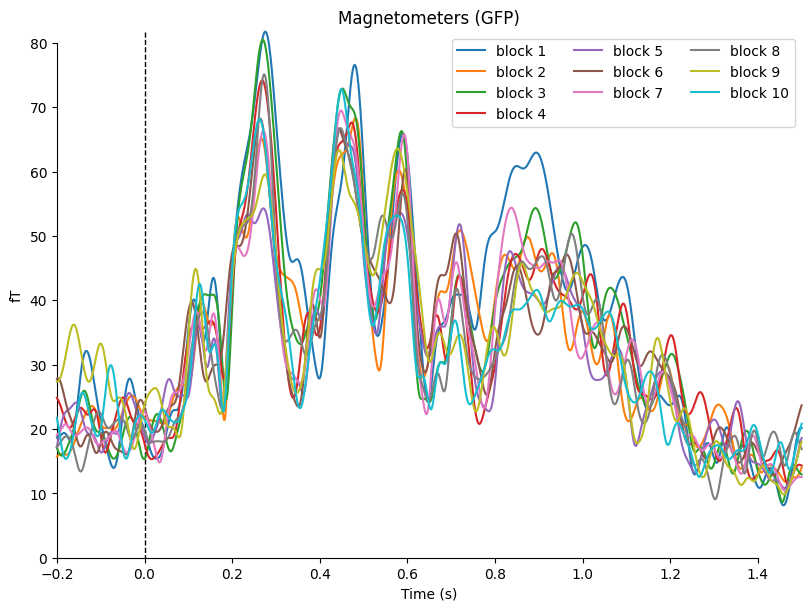

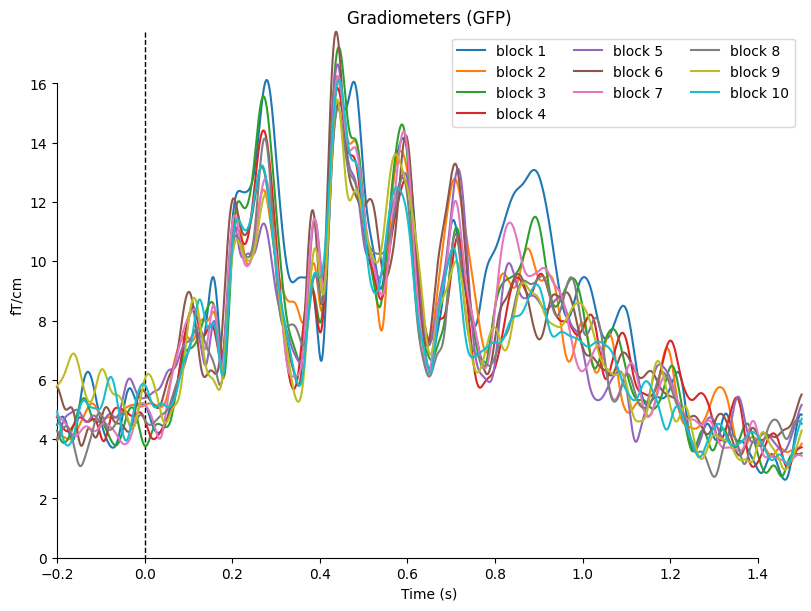

lengths od blocks :                            block1  block2  block3  block4  block5  block6  \
number of epochs averaged     144     144     144     144     144     144   

                           block7  block8  block9  block10  
number of epochs averaged     144     144     144      144  


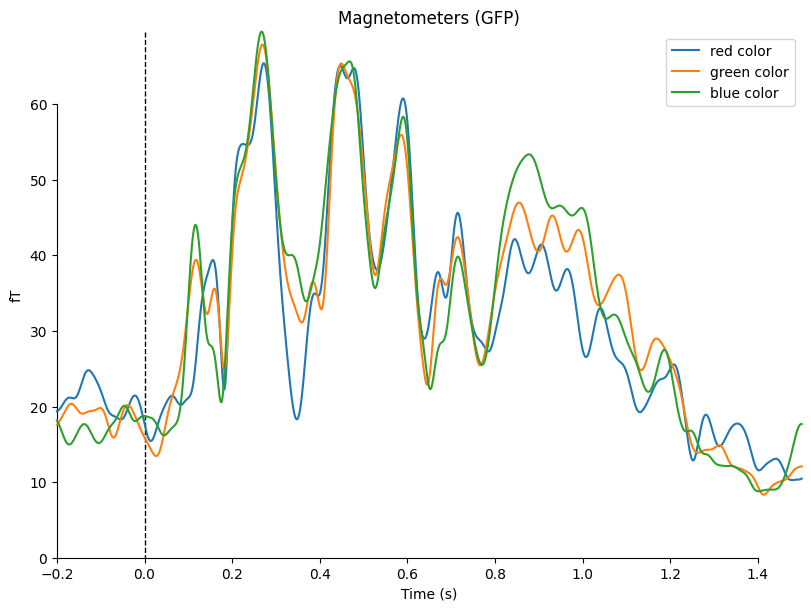

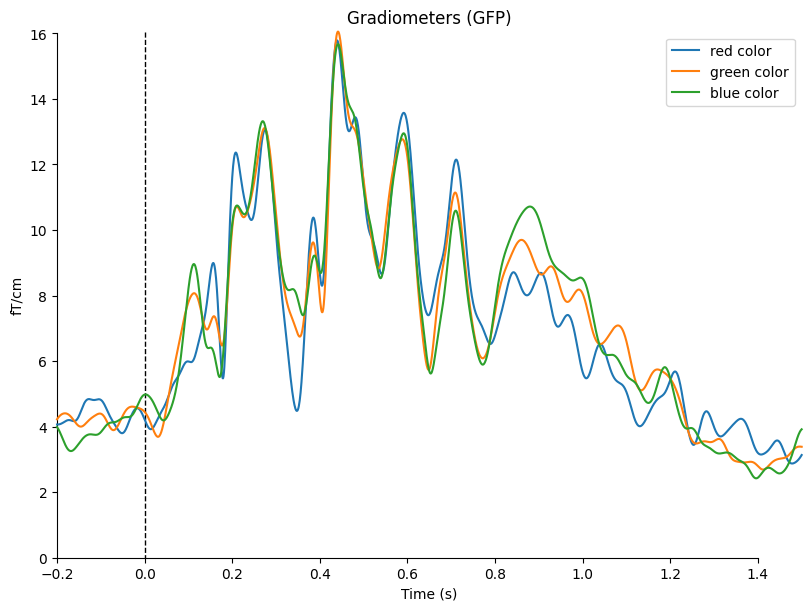

lengths of colors :                            red  green  blue
number of epochs averaged  446    502   492


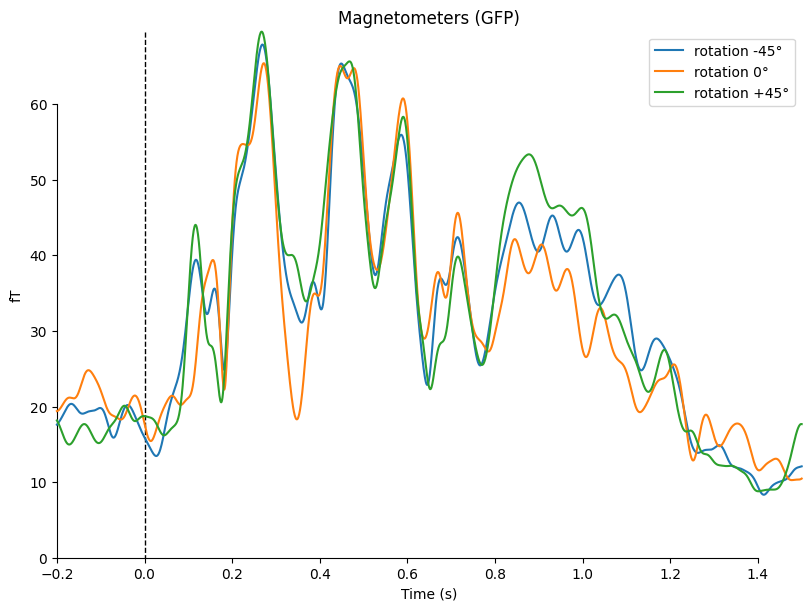

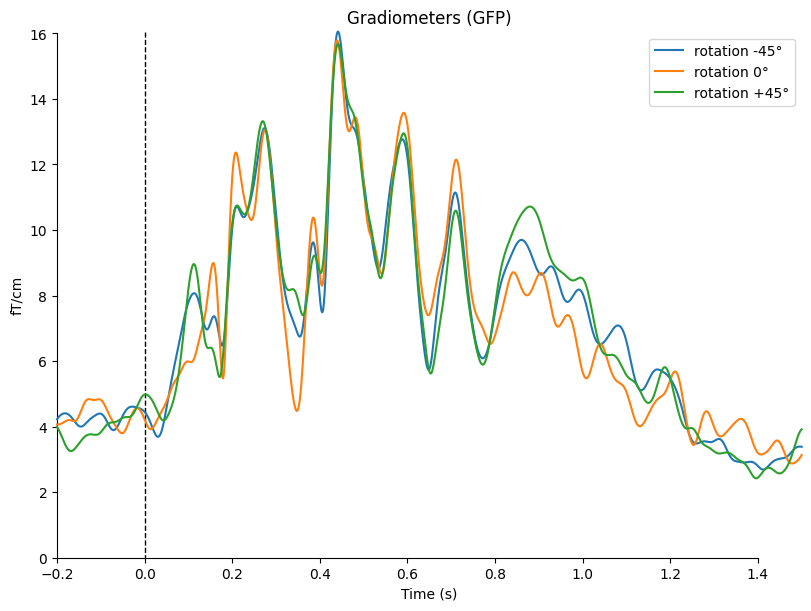

lengths of orientations :                            m45  p45    0
number of epochs averaged  502  492  446


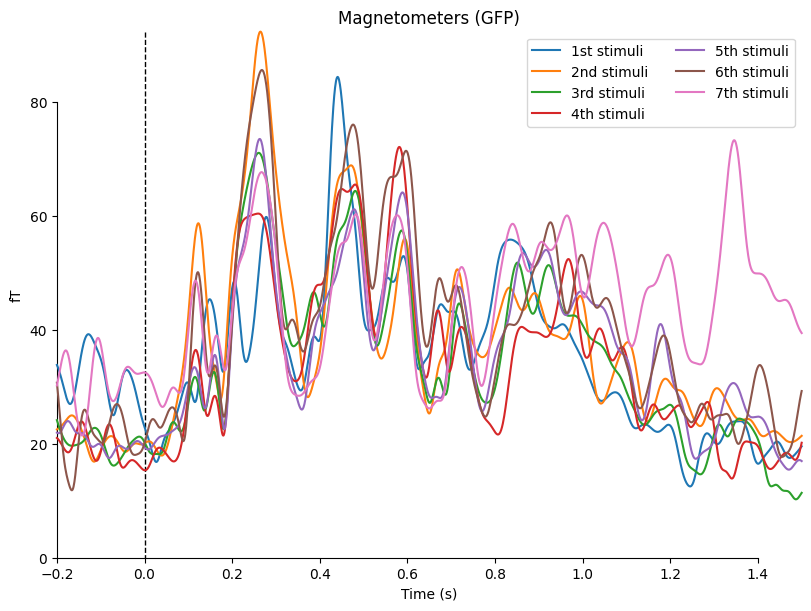

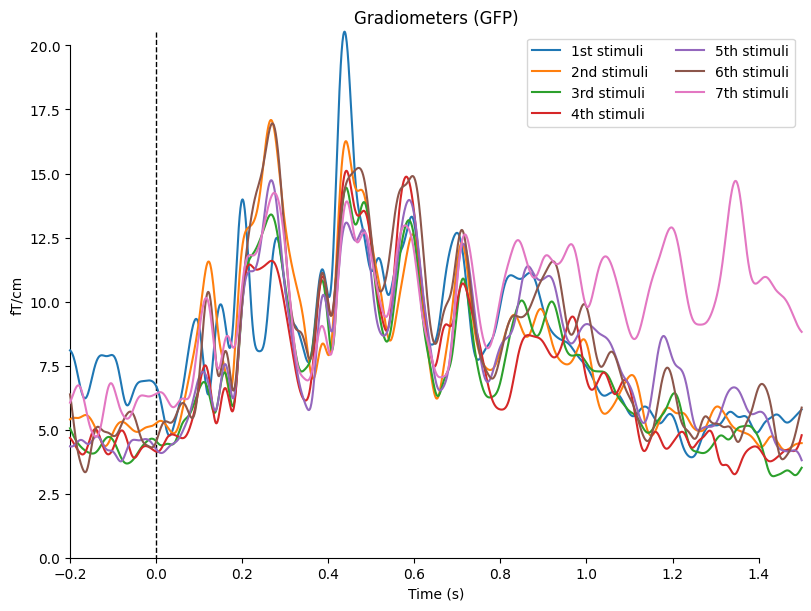

lengths of stimuli :                             S1   S2   S3   S4   S5  S6  S7
number of epochs averaged  360  270  270  180  180  90  90


In [120]:
print("🚨🚨  You can only compare evoked responses that have the same number of epochs 🚨🚨")
mne.viz.plot_compare_evokeds(evoked_blocks, legend='upper right'); print(f"lengths od blocks : {evoked_lenghts[['block1','block2','block3','block4','block5','block6','block7','block8','block9','block10']]}")
mne.viz.plot_compare_evokeds(evoked_colors, legend='upper right'); print(f"lengths of colors : {evoked_lenghts[['red','green','blue']]}")
mne.viz.plot_compare_evokeds(evoked_orientations, legend='upper right') ; print(f"lengths of orientations : {evoked_lenghts[['m45','p45','0']]}")
mne.viz.plot_compare_evokeds(evoked_S, legend='upper right'); print(f"lengths of stimuli : {evoked_lenghts[['S1','S2','S3','S4','S5','S6','S7']]}")

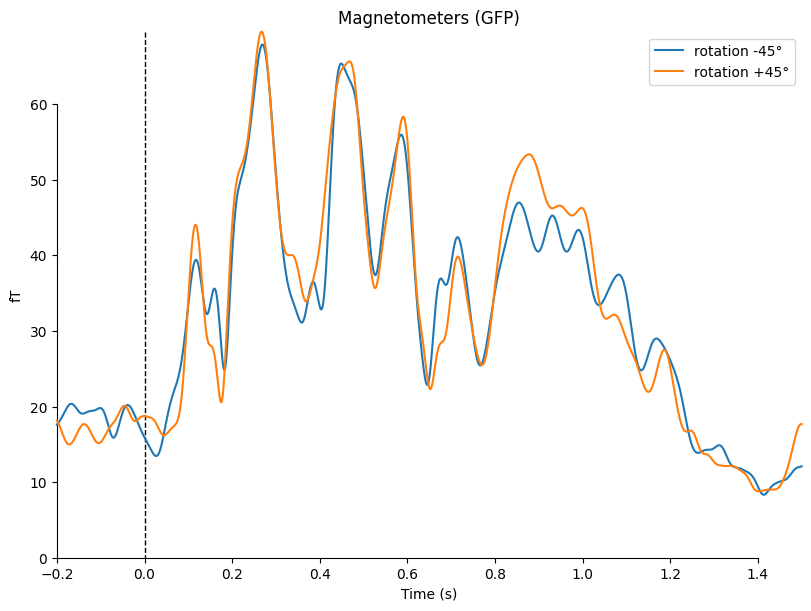

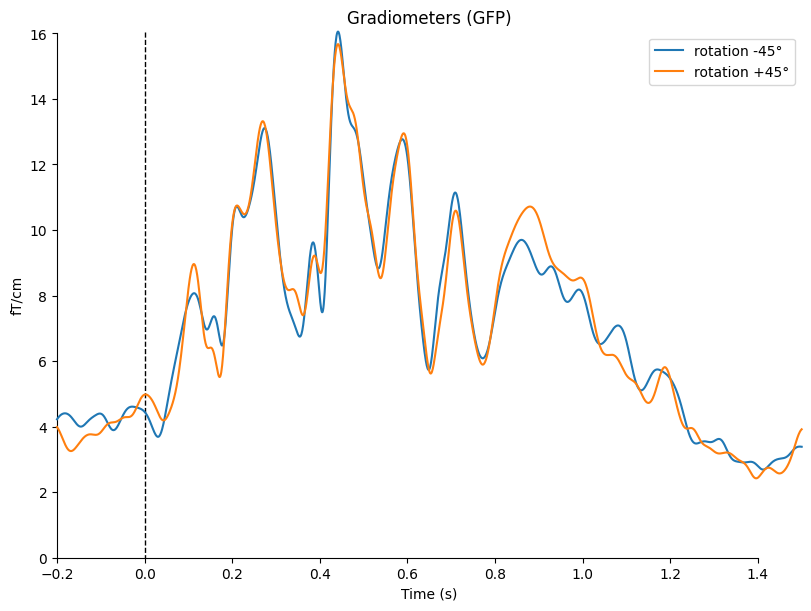

lengths of contrast : (number of epochs averaged    502
Name: m45, dtype: int64, number of epochs averaged    492
Name: p45, dtype: int64)


In [87]:
# pick what conditions to compare 
contrast = [evoked_m45, evoked_p45]
mne.viz.plot_compare_evokeds(contrast, legend='upper right')
print(f"lengths of contrast : {evoked_lenghts['m45'], evoked_lenghts['p45']}")

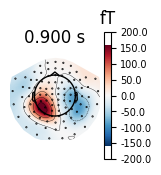

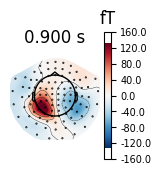

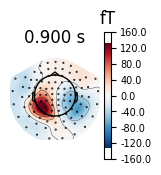

In [123]:
evoked_p45.plot_topomap(times=[0.9])
evoked_m45.plot_topomap(times=[0.9])

🚨🚨  You can only compare evoked responses that have the same number of epochs 🚨🚨
lengths of contrast number of epochs averaged    502
Name: m45, dtype: int64 number of epochs averaged    446
Name: 0, dtype: int64


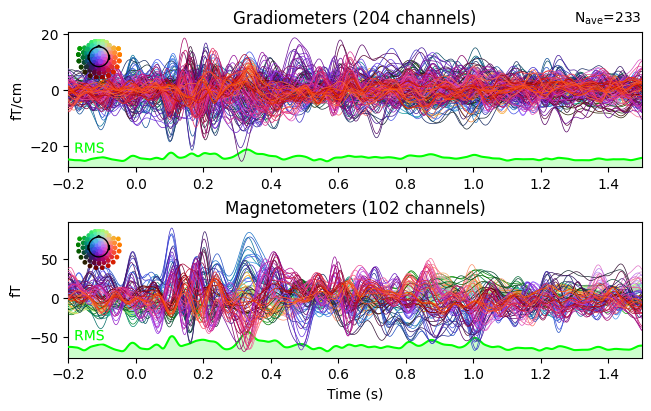

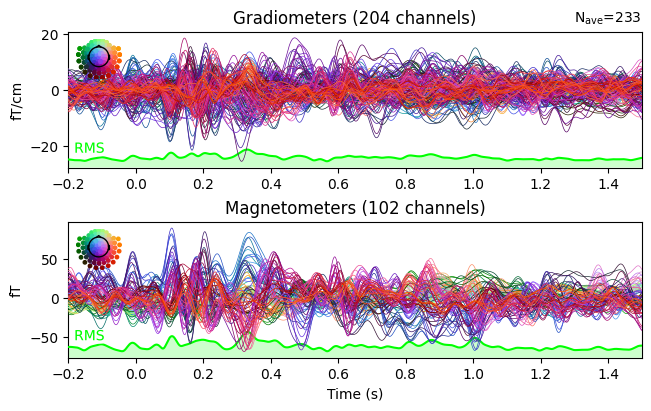

In [98]:
contrasts_size2 = [evoked_p45 , evoked_0]
print("🚨🚨  You can only compare evoked responses that have the same number of epochs 🚨🚨")
print(f"lengths of contrast", evoked_lenghts['m45'], evoked_lenghts['0'])


contrast = mne.combine_evoked(contrasts_size2, weights=[-1, 1])
contrast.plot(gfp=True)

# **Vizualising**

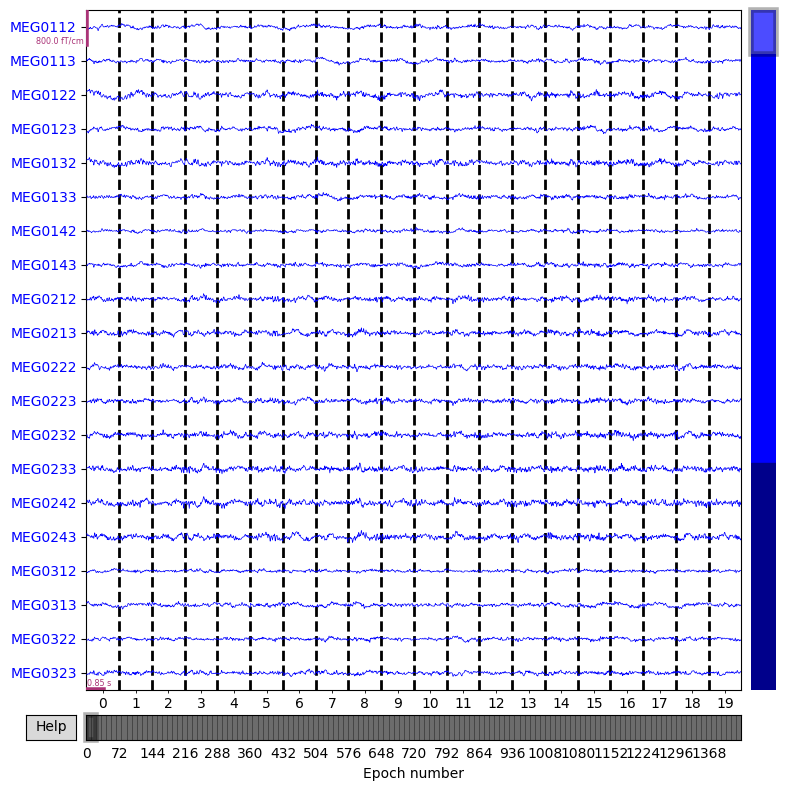

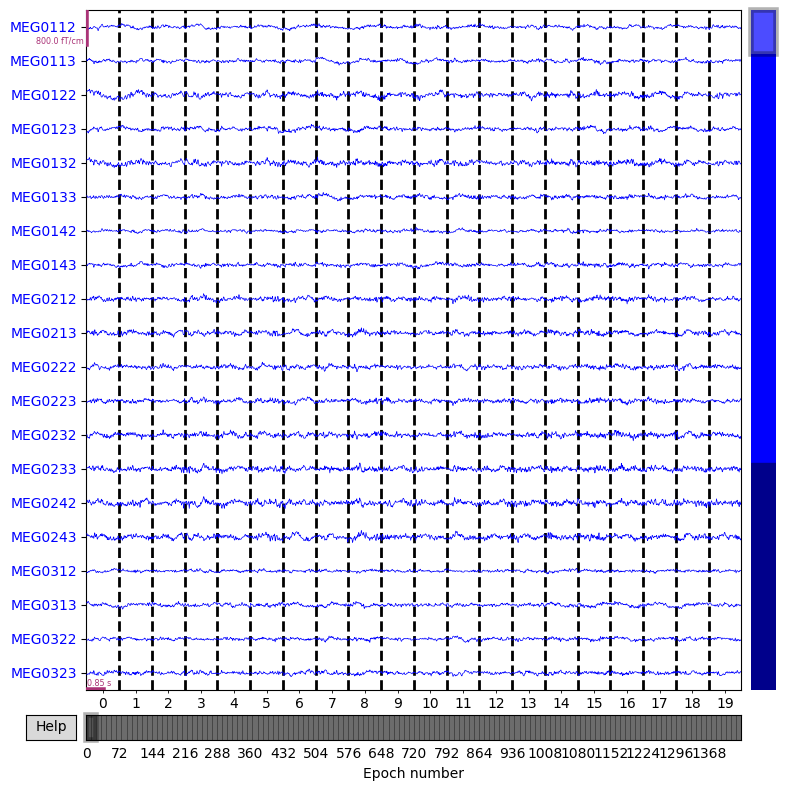

In [89]:
epochs.plot()

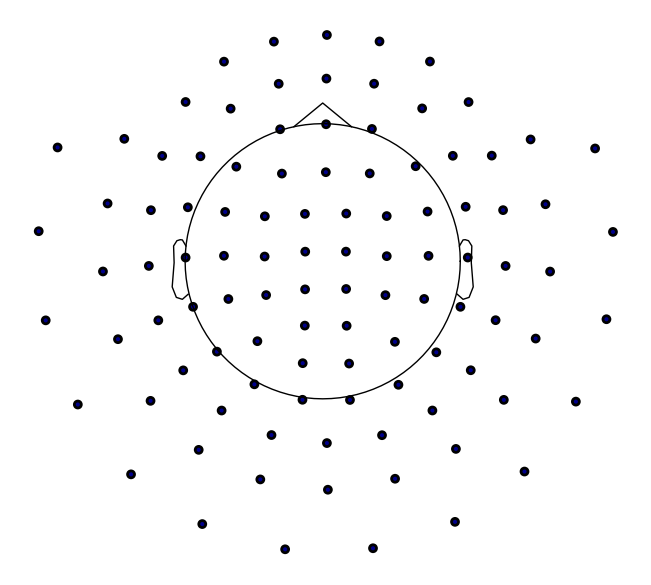

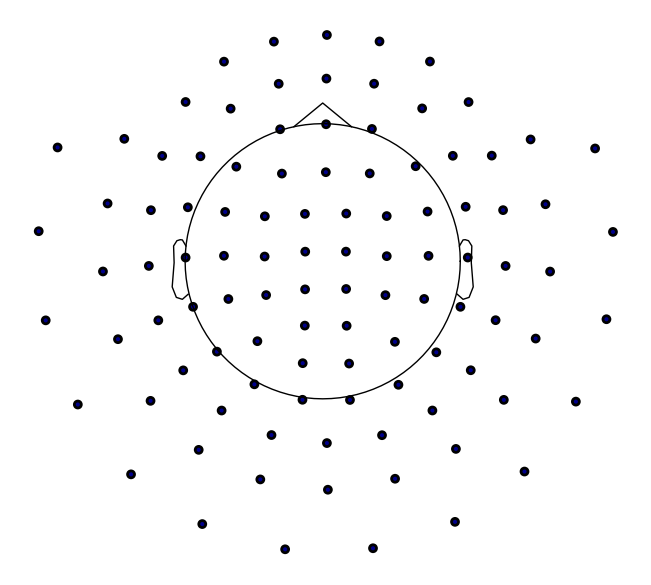

In [90]:
epochs.plot_sensors(ch_type="mag")

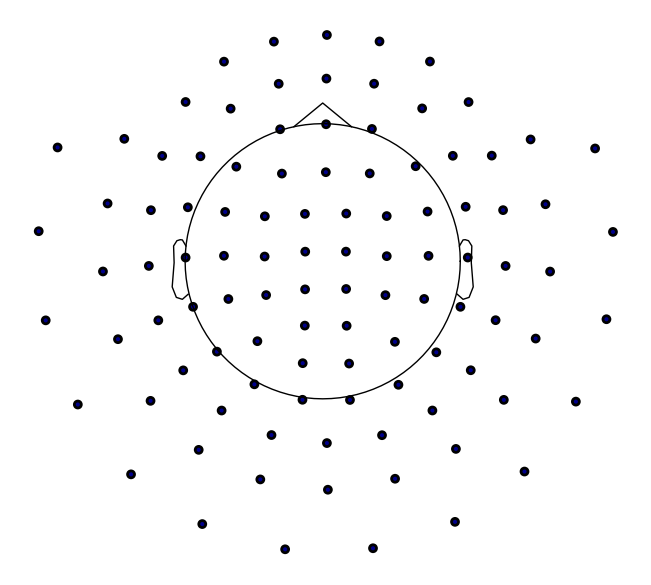

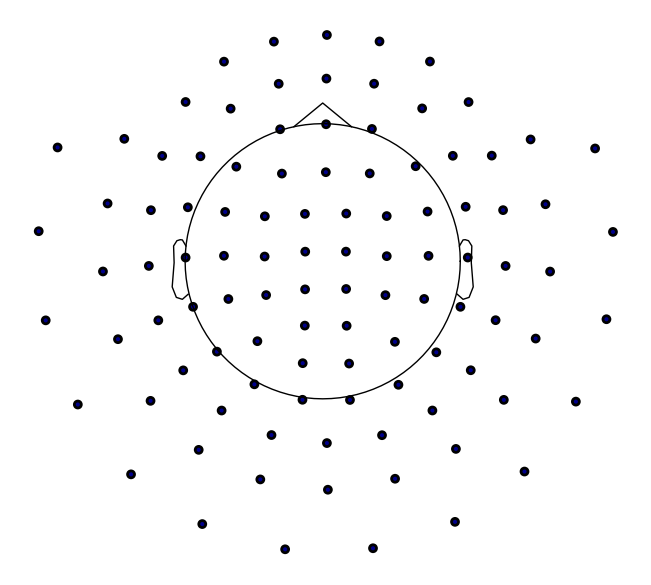

In [91]:
epochs.plot_sensors(ch_type="mag")

# **RAW FILE** detecting artefacts

In [92]:
ssp_projectors = raw.info["projs"]
raw.del_proj()

NameError: name 'raw' is not defined

In [ ]:
fig = epochs.compute_psd(tmax=np.inf, fmax=250).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)
# add some arrows at 60 Hz and its harmonics:
for ax in fig.axes[1:]:
    freqs = ax.lines[-1].get_xdata()
    psds = ax.lines[-1].get_ydata()
    for freq in (60, 120, 180, 240):
        idx = np.searchsorted(freqs, freq)
        ax.arrow(
            x=freqs[idx],
            y=psds[idx] + 18,
            dx=0,
            dy=-12,
            color="red",
            width=0.1,
            head_width=3,
            length_includes_head=True,
        )   

In [ ]:
events = mne.find_events(epochs)
print(events[:5])  # show the first 5

In [ ]:
event_dict = {
    "start of block": 255,
    "start of sequence": 128,
    "stim/S1": 129,
    "stim/S2": 130,
    "stim/S3": 131,
    "stim/S4": 132,
    "stim/S5": 133,
    "stim/S6": 134,
    "stim/S7": 135,
    "response presentation": 144,
    "response": 96,
}

In [ ]:
fig = mne.viz.plot_events(events, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp)

In [ ]:
sfreq = raw.info["sfreq"]
print(f"the sampling frequency (='sfreq') is {sfreq:.0f} Hz, meaning, the number of samples per second. Events are stored by number of sample. \nHaving the sampling frequency enables the events' extraction")

In [ ]:
events_table = mne.find_events(epochs)


In [ ]:
events_table = mne.find_events(raw, stim_channel='STI101')
events_table = pd.DataFrame(events_table, columns = ["sample_index", "zero", "event_code"])
events_table["event_times(s)"] = (events_table["sample_index"] - raw.first_samp) / sfreq
events_table["trigger_duration(ms)"] = events_table["event_times(s)"].diff()*1000
events_table

In [ ]:
events_table.to_csv(f"events_S0_B1.csv")

histograms of trigger distribution

In [ ]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]==144])
plt.show()

In [ ]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144][events_table["event_code"]!=128][events_table["event_code"]!=129])
plt.show()

In [ ]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144])
plt.show()

In [ ]:
for triggercode in events_table["event_code"].unique() : 
    plt.figure()
    x = events_table["trigger_duration(ms)"][1:,][events_table["event_code"]==triggercode]
    plt.hist(x)
    plt.title(f"histogramme des triggers pour trigger {triggercode}")
    plt.xlabel("temps (ms)")
    plt.show()

In [ ]:
event_ids = sorted(events_table["event_code"].unique())

# créer un mapping position -> event id
y_pos = np.arange(len(event_ids))
mapping = dict(zip(event_ids, y_pos))

plt.figure(figsize=(12,6))
plt.grid(alpha = 0.4)

for event_id in event_ids:

    subset = events_table[events_table["event_code"] == event_id]

    plt.scatter(
        subset["event_times(s)"],
        [mapping[event_id]] * len(subset),
        label=f"id:{event_id}; N:{len(subset)}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Event id")

# afficher les vrais labels
plt.yticks(y_pos, event_ids)
plt.show()

compter les triggers par bloc du coup

In [ ]:
Counter(events_table["event_code"])